## Initial Setup

We decided to use the [Steam Reviews Dataset](https://www.kaggle.com/datasets/najzeko/steam-reviews-2021/data) from Kaggle. The dataset contains reviews of games on Steam. We will be using the dataset to explore the data and answer questions about the data.

Because the dataset is large, we will be using a sample of the data. We will be using the first 1,000,000 rows of the dataset.

In [1]:
import pandas as pd
from IPython.display import display

df = pd.read_csv("../data/steam_reviews.csv", encoding="utf-8", nrows=1000000)

print("Sample shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Sample shape: (1000000, 23)

Column Names:
['Unnamed: 0', 'app_id', 'app_name', 'review_id', 'language', 'review', 'timestamp_created', 'timestamp_updated', 'recommended', 'votes_helpful', 'votes_funny', 'weighted_vote_score', 'comment_count', 'steam_purchase', 'received_for_free', 'written_during_early_access', 'author.steamid', 'author.num_games_owned', 'author.num_reviews', 'author.playtime_forever', 'author.playtime_last_two_weeks', 'author.playtime_at_review', 'author.last_played']


,Unnamed: 0,app_id,app_name,review_id,language,review,timestamp_created,timestamp_updated,recommended,votes_helpful,...,steam_purchase,received_for_free,written_during_early_access,author.steamid,author.num_games_owned,author.num_reviews,author.playtime_forever,author.playtime_last_two_weeks,author.playtime_at_review,author.last_played
0,0,292030,The Witcher 3: Wild Hunt,85185598,schinese,不玩此生遗憾，RPG游戏里的天花板，太吸引人了,1611381629,1611381629,True,0,...,True,False,False,76561199095369542,6,2,1909.0,1448.0,1909.0,1.611343e+09
1,1,292030,The Witcher 3: Wild Hunt,85185250,schinese,拔DIAO无情打桩机--杰洛特!!!,1611381030,1611381030,True,0,...,True,False,False,76561198949504115,30,10,2764.0,2743.0,2674.0,1.611386e+09
2,2,292030,The Witcher 3: Wild Hunt,85185111,schinese,巫师3NB,1611380800,1611380800,True,0,...,True,False,False,76561199090098988,5,1,1061.0,1061.0,1060.0,1.611384e+09
3,3,292030,The Witcher 3: Wild Hunt,85184605,english,"One of the best RPG's of all time, worthy of a...",1611379970,1611379970,True,0,...,True,False,False,76561199054755373,5,3,5587.0,3200.0,5524.0,1.611384e+09
4,4,292030,The Witcher 3: Wild Hunt,85184287,schinese,大作,1611379427,1611379427,True,0,...,True,False,False,76561199028326951,7,4,217.0,42.0,217.0,1.610788e+09


## Missing Values

Across the 100,000-row sample, the only column containing missing values is `review`, with **293 null entries**.

We kept these rows because a written review is optional on Steam. Users can submit a recommendation—thumbs up or thumbs down—without adding review text. Therefore, a missing `review` value represents valid behavior rather than a data-quality issue.

Dropping these rows would unnecessarily remove their other legitimate data. All other columns contain no missing values in this sample.

In [6]:
print(df.info())

print("\nMissing values: ")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\n")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 23 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Unnamed: 0                      1000000 non-null  int64  
 1   app_id                          1000000 non-null  int64  
 2   app_name                        1000000 non-null  str    
 3   review_id                       1000000 non-null  int64  
 4   language                        1000000 non-null  str    
 5   review                          998242 non-null   str    
 6   timestamp_created               1000000 non-null  int64  
 7   timestamp_updated               1000000 non-null  int64  
 8   recommended                     1000000 non-null  bool   
 9   votes_helpful                   1000000 non-null  int64  
 10  votes_funny                     1000000 non-null  int64  
 11  weighted_vote_score             1000000 non-null  float64
 12  comment_coun

,Unnamed: 0,app_id,review_id,timestamp_created,timestamp_updated,votes_helpful,votes_funny,weighted_vote_score,comment_count,author.steamid,author.num_games_owned,author.num_reviews,author.playtime_forever,author.playtime_last_two_weeks,author.playtime_at_review,author.last_played
count,1000000.000000,1000000.000000,1.000000e+06,1.000000e+06,1.000000e+06,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,9.976860e+05,1.000000e+06
mean,500000.028543,137653.276540,5.024635e+07,1.536537e+09,1.540020e+09,1.354286,1.374396e+05,0.140014,0.110916,7.656120e+16,128.462811,11.763607,1.019143e+04,83.725445,6.910500e+03,1.568400e+09
std,288675.710534,145203.141254,2.332212e+07,6.952888e+07,6.781931e+07,23.474932,2.429563e+07,0.232354,1.493333,3.292959e+08,267.229146,38.393893,3.265229e+04,548.635872,2.486934e+04,8.532309e+07
min,0.000000,70.000000,4.300000e+01,1.290320e+09,1.290320e+09,0.000000,0.000000e+00,0.000000,0.000000,7.656120e+16,0.000000,1.000000,0.000000e+00,0.000000,1.000000e+00,0.000000e+00
25%,249999.750000,620.000000,3.044572e+07,1.489235e+09,1.498630e+09,0.000000,0.000000e+00,0.000000,0.000000,7.656120e+16,26.000000,2.000000,9.640000e+02,0.000000,5.130000e+02,1.560865e+09
50%,500000.500000,4000.000000,5.347887e+07,1.562225e+09,1.568311e+09,0.000000,0.000000e+00,0.000000,0.000000,7.656120e+16,63.000000,5.000000,3.465000e+03,0.000000,1.640000e+03,1.592154e+09
75%,750000.250000,292030.000000,7.114404e+07,1.592769e+09,1.593889e+09,1.000000,0.000000e+00,0.467978,0.000000,7.656120e+16,140.000000,11.000000,9.257000e+03,0.000000,5.634000e+03,1.607051e+09
max,1000000.000000,292030.000000,8.521823e+07,1.611425e+09,1.611425e+09,7352.000000,4.294967e+09,0.990385,420.000000,7.656120e+16,20969.000000,5236.000000,3.336152e+06,20924.000000,3.062784e+06,1.611429e+09


## Closer look at the data

In [13]:
print("Unique games:", df["app_id"].nunique())
print("Game names:")
print(df["app_name"].value_counts().head(10))


print("\nLanguages:")
print(df["language"].value_counts().head(15))

# most common languages are english, simplified chinese, and russian

print("\nRcommendation counts:")
games = df.app_name.unique().tolist()
for game in games:
    print(game)
    print(df[df["app_name"] == game]["recommended"].value_counts())
    print("\n")

# the vast majority of reviews in this sample are recommended. 2,000 are not recommended

Unique games: 7
Game names:
app_name
The Witcher 3: Wild Hunt    469395
Portal 2                    232329
Counter-Strike: Source      118081
Garry's Mod                  92374
Half-Life                    57320
Half-Life 2: Episode Two     23500
X Rebirth                     7001
Name: count, dtype: int64

Languages:
language
english       392312
russian       185744
schinese      125667
brazilian      45571
turkish        44407
spanish        42013
polish         31777
german         31066
french         26499
koreana        21153
tchinese        8131
czech           7633
italian         5737
portuguese      4249
latam           4034
Name: count, dtype: int64

Rcommendation counts:
The Witcher 3: Wild Hunt
recommended
True     460252
False      9143
Name: count, dtype: int64


Half-Life
recommended
True     55312
False     2008
Name: count, dtype: int64


Counter-Strike: Source
recommended
True     113430
False      4651
Name: count, dtype: int64


Half-Life 2: Episode Two
recommende

## Visualizing the Data

This is the bar chart of the distribution of reviews of The Witcher 3: Wild Hunt. It is the most recommended game in steam review 2021 dataset. The most common review is a recommendation, followed by a non-recommendation. But this is also might not be all reviews of witcher wild hunt so is not entirely accurate in terms of raw numbers

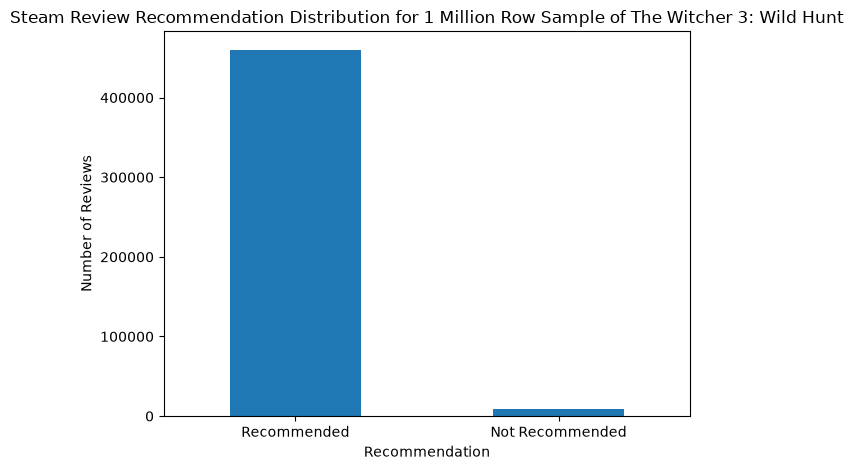

In [26]:
import matplotlib.pyplot as plt

recommendation_counts = df[df['app_name'] == "The Witcher 3: Wild Hunt"]["recommended"].value_counts().rename(
    index={True: "Recommended", False: "Not Recommended"}
)

# showing recommended vs not recommended
ax = recommendation_counts.plot(kind="bar")
ax.set_title("Steam Review Recommendation Distribution for 1 Million Row Sample of The Witcher 3: Wild Hunt")
ax.set_xlabel("Recommendation")
ax.set_ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Down here we see the lengths of steam reviews. majority fall under 100 characters, so short reviews are (somewhat obviously) more common than long reviews

count    1000000.000000
mean         135.238208
std          453.954100
min            0.000000
25%           12.000000
50%           34.000000
75%          100.000000
max       150000.000000
Name: review_length, dtype: float64


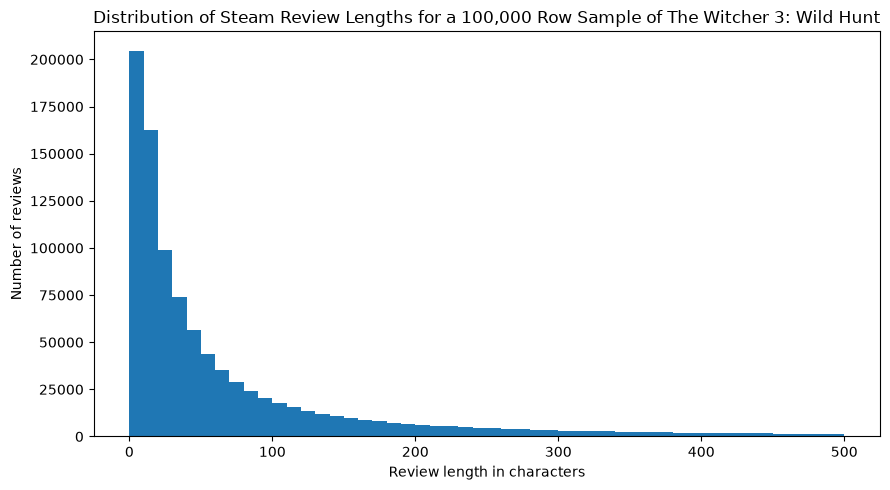

In [ ]:
df["review_length"] = df["review"].fillna("").str.len()
print(df["review_length"].describe())

plt.figure(figsize=(9, 5))
plt.hist(df.loc[df["review_length"] <= 500, "review_length"], bins=50)
plt.title("Distribution of Steam Review Lengths for a Million Row Sample of The Witcher 3: Wild Hunt")
plt.xlabel("Review length in characters")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

In [28]:
# calculating the number of english reviews, what portion is it of all reviews
english_df = df[(df["language"] == "english") &
                (df["review"].notna())].copy()

print("English reviews with not null text:", len(english_df))
print("Percentage of sample:", round(
    len(english_df) / len(df) * 100, 2
), "%")

English reviews with not null text: 391542
Percentage of sample: 39.15 %


**In the future we will cut down reviews to only english**